# Practical No. 06: Retrieval-Augmented Generation (RAG) using a Pre-trained LLM

### Name : Nikheel C Khadakabhavi
### PRN : 202401110020

**Aim:** Build a RAG application that answers questions from a domain-specific document collection, using document retrieval plus answer generation with a pretrained LLM, and compare its answers with the same LLM used *without* retrieval.

**Domain:** Academic handbook of a (fictional) engineering college, *Sahyadri Institute of Technology (SIT)*. A fictional domain is chosen on purpose: the LLM cannot know these rules from pre-training, so the benefit of retrieval is clearly visible.

## Theory
A pretrained LLM stores knowledge only in its weights. It can be outdated, and it hallucinates on private or domain-specific facts. RAG fixes this by fetching relevant text at question time and putting it into the prompt.

**Pipeline**
1. **Ingest:** load documents.
2. **Chunk:** split into small overlapping passages.
3. **Embed:** convert each chunk to a vector with a sentence-embedding model.
4. **Index:** store the vectors (cosine similarity search).
5. **Retrieve:** embed the question and take the top-k most similar chunks.
6. **Augment:** build a prompt = instruction + retrieved context + question.
7. **Generate:** the LLM answers using the context.

**Models used**
- Embeddings: `sentence-transformers/all-MiniLM-L6-v2`
- LLM: `Qwen/Qwen2.5-0.5B-Instruct` (small, runs on CPU; you can switch to a larger model if you have a GPU)

## Step 1: Install and import libraries

In [1]:
!pip install -q transformers sentence-transformers accelerate pandas matplotlib rouge-score

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import re, os, glob, time, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForCausalLM
from rouge_score import rouge_scorer

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


## Step 2: Domain-specific document collection
Ten short documents from the SIT Academic Handbook. To use your own data instead, put `.txt` files in a folder called `docs/` and run the optional cell below.

In [3]:
documents = {
"attendance_policy": """Attendance Policy. A student must have at least 80% attendance in every course to be eligible for the end-semester examination. Students with attendance between 70% and 79% may apply for condonation by submitting a medical certificate and paying a condonation fee of Rs. 500 per course. Students with attendance below 70% are detained and must repeat the course in the next academic year.""",

"grading_system": """Grading System. SIT follows a 10-point grading scale. Marks of 90 and above earn grade O (10 points), 80 to 89 earn A+ (9 points), 70 to 79 earn A (8 points), 60 to 69 earn B+ (7 points), 55 to 59 earn B (6 points), 50 to 54 earn C (5 points), 40 to 49 earn P (4 points). Marks below 40 earn grade F (fail, 0 points). SGPA is calculated per semester and CGPA is the credit-weighted average across all semesters.""",

"backlog_atkt_rules": """Backlog and ATKT Rules. Under the Allowed To Keep Terms (ATKT) rule, a student can carry forward a maximum of 3 backlog courses into the next academic year. A student with more than 3 backlog courses is placed in year-down and must repeat the year. The re-examination fee for a backlog course is Rs. 1200 per course. A backlog course must be cleared within 3 attempts.""",

"library_rules": """Library Rules. Each student may borrow up to 4 books at a time for a period of 14 days. A late return fine of Rs. 5 per day per book is charged. The reading hall is open from 8:00 AM to 10:00 PM on all working days. The digital library and e-journals are accessible 24x7 through the campus portal. Lost books must be replaced or paid for at twice the book price.""",

"hostel_rules": """Hostel Rules. The hostel curfew is 9:30 PM for first-year students and 10:30 PM for all other years. The mess fee is Rs. 3800 per month. Guests are permitted only in the visitors room between 4:00 PM and 6:00 PM on Saturdays and Sundays. Cooking appliances and heaters are not allowed in hostel rooms. Late entry more than three times in a month results in a written warning to parents.""",

"scholarship_policy": """Scholarship Policy. The SIT Merit Scholarship gives a 50% tuition fee waiver to students with a CGPA of 9.0 or above, and a 25% waiver to students with a CGPA between 8.5 and 8.99. Applications must be submitted to the accounts office by 31 August each year. The scholarship is reviewed every year and withdrawn if the CGPA drops below 8.5 or if the student has any active backlog.""",

"internship_requirement": """Internship Requirement. Every student must complete a mandatory internship of 8 weeks after the sixth semester. The internship carries 4 credits. A signed completion certificate from the host organization and an internship report must be submitted to the training and placement cell within 15 days of finishing the internship. Internships may be done in industry, a research lab or an approved startup.""",

"revaluation_rules": """Revaluation Rules. A student may apply for revaluation of an answer script within 7 days of the declaration of results. The revaluation fee is Rs. 600 per course. The revaluation result is announced within 21 days. If the revaluation marks differ by more than 10% from the original marks, a third examiner evaluates the script and the average of the two nearest marks is awarded.""",

"placement_policy": """Placement Policy. To sit for campus placements a student must have a CGPA of at least 6.5 and no active backlog. A student can receive a maximum of 2 offers through campus placement. A student who receives an offer with a package of 10 LPA or more is considered a dream offer and may sit for further drives. Students must carry their SIT ID card to every placement drive.""",

"graduation_and_conduct": """Graduation and Conduct. To graduate with a B.Tech degree, a student must earn a minimum of 160 credits and have a CGPA of at least 5.0. Mobile phones are not allowed inside laboratories. Plagiarism is strictly prohibited: a project report with more than 25% similarity in the plagiarism check is rejected and must be resubmitted. Wearing the ID card on campus is compulsory.""",
}
print(len(documents), "documents loaded")
print("Total words:", sum(len(t.split()) for t in documents.values()))

10 documents loaded
Total words: 682


**Optional:** load your own `.txt` documents from a folder named `docs/` (skip this cell if you use the built-in handbook).

In [4]:
# Uncomment to use your own documents
# documents = {}
# for path in glob.glob("docs/*.txt"):
#     with open(path, encoding="utf-8") as f:
#         documents[os.path.basename(path)] = f.read()
# print(len(documents), "documents loaded from docs/")

## Step 3: Chunking
Documents are split into overlapping word windows. Overlap keeps a sentence that falls on a boundary from losing its context.

In [5]:
def chunk_text(text, chunk_size=60, overlap=15):
    words = text.split()
    step = chunk_size - overlap
    chunks = []
    for start in range(0, len(words), step):
        piece = words[start:start + chunk_size]
        if piece:
            chunks.append(" ".join(piece))
        if start + chunk_size >= len(words):
            break
    return chunks

chunks, chunk_meta = [], []
for doc_name, text in documents.items():
    for i, ch in enumerate(chunk_text(text)):
        chunks.append(ch)
        chunk_meta.append({"doc": doc_name, "chunk_id": i})

print("Total chunks:", len(chunks))
print("\nSample chunk:\n", chunks[0])

Total chunks: 20

Sample chunk:
 Attendance Policy. A student must have at least 80% attendance in every course to be eligible for the end-semester examination. Students with attendance between 70% and 79% may apply for condonation by submitting a medical certificate and paying a condonation fee of Rs. 500 per course. Students with attendance below 70% are detained and must repeat the course in the


## Step 4: Embeddings and vector index

In [6]:
embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)

# normalised embeddings => dot product == cosine similarity
chunk_embeddings = embedder.encode(chunks, normalize_embeddings=True, show_progress_bar=False)
print("Embedding matrix shape:", chunk_embeddings.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding matrix shape: (20, 384)


## Step 5: Retriever (top-k cosine similarity search)

In [7]:
def retrieve(query, k=3):
    q = embedder.encode([query], normalize_embeddings=True)[0]
    scores = chunk_embeddings @ q
    top = np.argsort(-scores)[:k]
    return [{"chunk": chunks[i], "doc": chunk_meta[i]["doc"], "score": float(scores[i])} for i in top]

# quick test
for r in retrieve("How many books can I borrow from the library?", k=3):
    print(f"[{r['score']:.3f}] ({r['doc']}) {r['chunk'][:110]}...")

[0.616] (library_rules) Library Rules. Each student may borrow up to 4 books at a time for a period of 14 days. A late return fine of ...
[0.456] (library_rules) working days. The digital library and e-journals are accessible 24x7 through the campus portal. Lost books mus...
[0.261] (backlog_atkt_rules) Backlog and ATKT Rules. Under the Allowed To Keep Terms (ATKT) rule, a student can carry forward a maximum of ...


## Step 6: Load the pretrained LLM
The first run downloads the model (about 1 GB).

In [8]:
model_name = "Qwen/Qwen2.5-0.5B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(model_name)
llm = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
).to(device)
llm.eval()
print("LLM loaded:", model_name)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

LLM loaded: Qwen/Qwen2.5-0.5B-Instruct


## Step 7: Generation functions
- `answer_without_rag`: the question goes straight to the LLM.
- `answer_with_rag`: retrieved chunks are inserted into the prompt, and the model is told to answer only from them.

Greedy decoding (`do_sample=False`) is used so both systems are compared fairly and results are repeatable.

In [9]:
def generate(messages, max_new_tokens=120):
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, return_tensors="pt").to(device)
    with torch.no_grad():
        out = llm.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                           pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

def answer_without_rag(question):
    messages = [
        {"role": "system", "content": "You are a helpful assistant. Answer briefly."},
        {"role": "user", "content": question},
    ]
    return generate(messages)

def build_rag_prompt(question, retrieved):
    context = "\n\n".join(f"[{i+1}] {r['chunk']}" for i, r in enumerate(retrieved))
    return (
        "Answer the question using ONLY the context below. "
        "If the answer is not in the context, say \"I don't know\". Answer briefly.\n\n"
        f"Context:\n{context}\n\nQuestion: {question}"
    )

def answer_with_rag(question, k=3):
    retrieved = retrieve(question, k)
    messages = [
        {"role": "system", "content": "You are a helpful assistant for SIT students."},
        {"role": "user", "content": build_rag_prompt(question, retrieved)},
    ]
    return generate(messages), retrieved

## Step 8: Try one question with both systems

In [10]:
q = "What is the minimum attendance required to write the end-semester exam at SIT?"

print("QUESTION:", q)
print("\n--- Without RAG ---")
print(textwrap.fill(answer_without_rag(q), 100))

ans, ctx = answer_with_rag(q)
print("\n--- With RAG ---")
print(textwrap.fill(ans, 100))
print("\nRetrieved from:", [c["doc"] for c in ctx])

QUESTION: What is the minimum attendance required to write the end-semester exam at SIT?

--- Without RAG ---
The minimum attendance requirement for writing the end-semester exam at SIT (Sri Lanka Institute of
Technology) varies depending on the course and institution. Typically, students need to attend 80%
or more of their scheduled classes to be eligible for the exam. However, specific requirements can
change based on the syllabus and grading criteria of each course. It's best to check with your
academic advisor or the relevant department for the most accurate information.

--- With RAG ---
To be eligible for the end-semester examination at SIT, a student must have at least 80% attendance.

Retrieved from: ['attendance_policy', 'placement_policy', 'grading_system']


## Step 9: Evaluation set
Ten questions with a reference answer, a few **keywords** that a correct answer must contain, and the **source document** that holds the answer.

In [11]:
eval_set = [
 {"q": "What is the minimum attendance required to be eligible for the end-semester exam?",
  "ref": "At least 80% attendance in every course.", "kw": ["80"], "src": "attendance_policy"},
 {"q": "What is the condonation fee for students having 70 to 79 percent attendance?",
  "ref": "Rs. 500 per course along with a medical certificate.", "kw": ["500"], "src": "attendance_policy"},
 {"q": "How many backlog courses can a student carry forward under the ATKT rule?",
  "ref": "A maximum of 3 backlog courses.", "kw": ["3"], "src": "backlog_atkt_rules"},
 {"q": "What is the late return fine per day for a library book?",
  "ref": "Rs. 5 per day per book.", "kw": ["5"], "src": "library_rules"},
 {"q": "What is the hostel curfew time for first-year students?",
  "ref": "9:30 PM.", "kw": ["9:30"], "src": "hostel_rules"},
 {"q": "What scholarship does a student with CGPA of 9.0 or above get?",
  "ref": "A 50% tuition fee waiver under the SIT Merit Scholarship.", "kw": ["50"], "src": "scholarship_policy"},
 {"q": "How long is the mandatory internship and when is it done?",
  "ref": "8 weeks, after the sixth semester.", "kw": ["8", "sixth"], "src": "internship_requirement"},
 {"q": "Within how many days of the result must a student apply for revaluation?",
  "ref": "Within 7 days of the declaration of results.", "kw": ["7"], "src": "revaluation_rules"},
 {"q": "What is the minimum CGPA needed to sit for campus placements?",
  "ref": "A CGPA of at least 6.5 with no active backlog.", "kw": ["6.5"], "src": "placement_policy"},
 {"q": "How many credits are required to graduate with a B.Tech degree at SIT?",
  "ref": "A minimum of 160 credits.", "kw": ["160"], "src": "graduation_and_conduct"},
]
print(len(eval_set), "evaluation questions")

10 evaluation questions


## Step 10: Run both systems and compute metrics

| Metric | Meaning |
|---|---|
| **Keyword accuracy** | Fraction of required keywords present in the answer (1.0 = fully correct) |
| **ROUGE-L F1** | Text overlap between answer and reference answer |
| **Retrieval hit** | Whether the correct source document appears in the top-k chunks (RAG only) |

In [12]:
scorer = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)

def keyword_score(answer, keywords):
    a = answer.lower()
    return sum(1 for k in keywords if k.lower() in a) / len(keywords)

rows = []
for item in eval_set:
    t0 = time.time(); a_plain = answer_without_rag(item["q"]); t_plain = time.time() - t0
    t0 = time.time(); a_rag, ctx = answer_with_rag(item["q"], k=3); t_rag = time.time() - t0

    rows.append({
        "question": item["q"],
        "answer_no_rag": a_plain,
        "answer_rag": a_rag,
        "kw_no_rag": keyword_score(a_plain, item["kw"]),
        "kw_rag": keyword_score(a_rag, item["kw"]),
        "rouge_no_rag": scorer.score(item["ref"], a_plain)["rougeL"].fmeasure,
        "rouge_rag": scorer.score(item["ref"], a_rag)["rougeL"].fmeasure,
        "retrieval_hit": item["src"] in [c["doc"] for c in ctx],
        "time_no_rag_s": t_plain,
        "time_rag_s": t_rag,
    })

results = pd.DataFrame(rows)
results.index = [f"Q{i+1}" for i in range(len(results))]
results[["kw_no_rag", "kw_rag", "rouge_no_rag", "rouge_rag", "retrieval_hit"]].round(3)

,kw_no_rag,kw_rag,rouge_no_rag,rouge_rag,retrieval_hit
Q1,0.0,1.0,0.077,0.348,True
Q2,0.0,1.0,0.083,0.364,True
Q3,0.0,1.0,0.083,0.414,True
Q4,1.0,1.0,0.118,1.000,True
Q5,0.0,1.0,0.044,0.400,True
Q6,0.0,0.0,0.067,0.421,True
Q7,0.5,1.0,0.044,0.600,True
Q8,0.0,1.0,0.500,0.857,True
Q9,0.0,1.0,0.062,0.519,True
Q10,0.0,1.0,0.150,0.435,True


## Step 11: Side-by-side answers

In [13]:
for idx, row in results.iterrows():
    print(f"{idx}. {row['question']}")
    print("   Reference :", eval_set[int(idx[1:]) - 1]["ref"])
    print("   No RAG    :", textwrap.shorten(row["answer_no_rag"], 160))
    print("   With RAG  :", textwrap.shorten(row["answer_rag"], 160))
    print()

Q1. What is the minimum attendance required to be eligible for the end-semester exam?
   Reference : At least 80% attendance in every course.
   No RAG    : The minimum attendance required to be eligible for the end-semester exam can vary depending on the institution and specific requirements of the course or [...]
   With RAG  : To be eligible for the end-semester examination, a student must have at least 80% attendance.

Q2. What is the condonation fee for students having 70 to 79 percent attendance?
   Reference : Rs. 500 per course along with a medical certificate.
   No RAG    : The condonation fee for students with 70 to 79% attendance is typically $15 per semester.
   With RAG  : Rs. 500

Q3. How many backlog courses can a student carry forward under the ATKT rule?
   Reference : A maximum of 3 backlog courses.
   No RAG    : Under the Advanced Technology Knowledge Test (ATKT) rules, students can carry forward up to 10 courses at any given time. This limit is set by the test's [

## Step 12: Summary and comparison chart

                        Without RAG  With RAG
Keyword accuracy              0.150     0.900
ROUGE-L F1                    0.123     0.536
Avg. response time (s)        2.229     0.672

Retrieval hit rate @3: 1.0


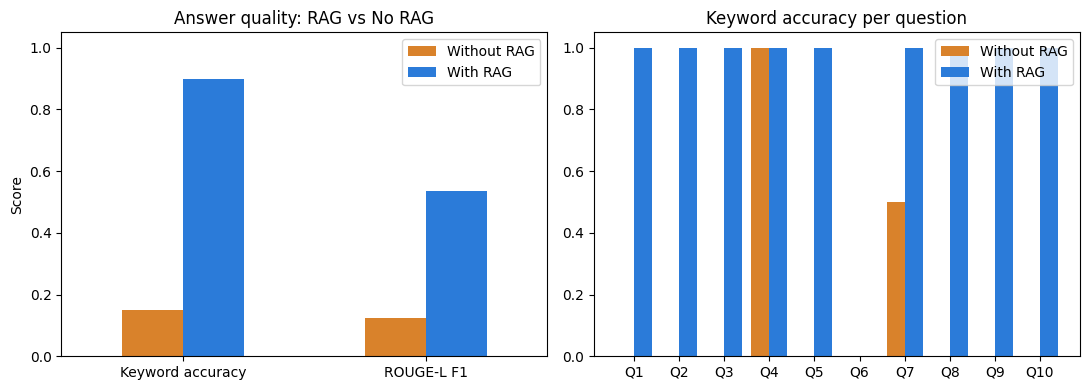

In [14]:
summary = pd.DataFrame({
    "Without RAG": [results.kw_no_rag.mean(), results.rouge_no_rag.mean(), results.time_no_rag_s.mean()],
    "With RAG":    [results.kw_rag.mean(),    results.rouge_rag.mean(),    results.time_rag_s.mean()],
}, index=["Keyword accuracy", "ROUGE-L F1", "Avg. response time (s)"]).round(3)
print(summary)
print("\nRetrieval hit rate @3:", results.retrieval_hit.mean())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
summary.iloc[:2].plot(kind="bar", ax=ax[0], rot=0, color=["#d9822b", "#2b7bd9"])
ax[0].set_title("Answer quality: RAG vs No RAG"); ax[0].set_ylim(0, 1.05); ax[0].set_ylabel("Score")

x = np.arange(len(results)); w = 0.4
ax[1].bar(x - w/2, results.kw_no_rag, w, label="Without RAG", color="#d9822b")
ax[1].bar(x + w/2, results.kw_rag, w, label="With RAG", color="#2b7bd9")
ax[1].set_xticks(x); ax[1].set_xticklabels(results.index)
ax[1].set_title("Keyword accuracy per question"); ax[1].legend()
plt.tight_layout(); plt.show()

## Step 13: Interactive Q&A (try your own questions)

In [15]:
def ask(question, k=3, show_context=True):
    ans, ctx = answer_with_rag(question, k)
    print("Q:", question)
    print("\nRAG answer   :", textwrap.fill(ans, 100))
    print("No-RAG answer:", textwrap.fill(answer_without_rag(question), 100))
    if show_context:
        print("\nSources:")
        for c in ctx:
            print(f"  [{c['score']:.3f}] {c['doc']}")

ask("Can a first-year student return to the hostel at 10 PM?")

Q: Can a first-year student return to the hostel at 10 PM?

RAG answer   : Yes, according to the hostel rules, a first-year student can return to the hostel at 10 PM.
No-RAG answer: No, a first-year student cannot return to the hostel at 10 PM because that time is considered
midnight in most countries and places. The hostel typically operates from 8 AM to 6 PM, not from
midnight to noon.

Sources:
  [0.610] hostel_rules
  [0.569] hostel_rules
  [0.457] library_rules


## Observations
- **Without RAG** the LLM has never seen the SIT handbook, so it either gives generic or invented numbers (for example a typical 75% attendance rule instead of 80%) or avoids the question. This is *hallucination* on domain-specific data.
- **With RAG** the retriever supplies the exact policy text, so the answers match the handbook and the sources can be traced back, which makes the answers verifiable.
- Retrieval quality limits answer quality: when the correct chunk is not in the top-k, the generator cannot answer correctly. The retrieval hit rate shows this.
- RAG adds latency (embedding the query and a longer prompt) but needs **no retraining**. Updating knowledge only means editing documents and re-indexing.
- Small LLMs such as Qwen2.5-0.5B may still make occasional mistakes even with correct context; a larger model improves faithfulness.

## Conclusion
A RAG application was built with chunking, sentence-embedding retrieval, and a pretrained LLM for generation. On the domain-specific handbook, RAG clearly improved keyword accuracy and ROUGE-L over the plain LLM, showing that retrieval grounds the model in external knowledge and reduces hallucination without fine-tuning.
